# 01 · Exploratory Data Analysis: `application_train`

**Goal of this notebook:** understand the main application table before building any model,
and collect the first evidence for the hypotheses written in the README:

| # | Question | What EDA can already tell us |
|---|---|---|
| H1 | Non-linearity | Does default rate change *linearly* with key features? |
| H2 | Missing data | Is *missingness itself* related to default? |
| H4 | Class imbalance | How rare are defaults, and what does that do to naive metrics? |

The six history tables (bureau, previous applications, installments, …) are explored in a later notebook.

In [1]:
import sys
sys.path.insert(0, "..")  # make `src/` importable from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load, mem_mb
from src.viz import set_style, save, BLUE, ORANGE, INK_2, GRID, SURFACE

set_style()
pd.set_option("display.max_columns", 50)

## 0 · Load
`load()` reads the CSV and downcasts dtypes (float64 → float32, text → category), which cuts memory by ~70%.

In [2]:
train = load("application_train")
print(f"{train.shape[0]:,} applications × {train.shape[1]} columns  |  {mem_mb(train):.0f} MB in memory")
print(train.dtypes.map(lambda d: d.name).value_counts().to_string())

307,511 applications × 122 columns  |  95 MB in memory
float32     65
int8        37
category    16
int32        2
int16        2


## 1 · The target: how rare is "payment difficulty"?
`TARGET = 1` means the client was late by more than X days on at least one of the first Y instalments
(X and Y are not disclosed). It is a *payment difficulty* flag, not a write-off.

In [3]:
counts = train["TARGET"].value_counts().sort_index()
summary = pd.DataFrame({"clients": counts, "share": (counts / counts.sum()).map("{:.2%}".format)})
summary.index = ["0 · repaid without difficulty", "1 · payment difficulty"]
summary

,clients,share
0 · repaid without difficulty,282686,91.93%
1 · payment difficulty,24825,8.07%


**Why accuracy is useless here:** a "model" that predicts *nobody* will default is right ~92% of the time
and catches zero risky clients. We will therefore judge models by how well they **rank** clients
(ROC-AUC, PR-AUC) and how trustworthy their probabilities are (calibration), never by accuracy.

In [4]:
base_rate = train["TARGET"].mean()
print(f"Accuracy of 'predict 0 for everyone': {1 - base_rate:.2%}")
print(f"Risky clients it catches:             0 of {int(train['TARGET'].sum()):,}")

Accuracy of 'predict 0 for everyone': 91.93%
Risky clients it catches:             0 of 24,825


## 2 · Missing data: the big picture
Before treating missing values as a nuisance, look at *how much* is missing and *where*.

In [5]:
miss = train.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
bins = pd.cut(miss, [0, 0.01, 0.10, 0.50, 1.0], labels=["< 1%", "1–10%", "10–50%", "> 50%"])
print(f"{len(miss)} of {train.shape[1]} columns have missing values")
print(bins.value_counts().sort_index().rename("columns").to_string())

67 of 122 columns have missing values
< 1%      10
1–10%      0
10–50%    16
> 50%     41


In [6]:
miss.head(15).map("{:.1%}".format).rename("missing share").to_frame()

,missing share
COMMONAREA_MEDI,69.9%
COMMONAREA_AVG,69.9%
COMMONAREA_MODE,69.9%
NONLIVINGAPARTMENTS_MODE,69.4%
NONLIVINGAPARTMENTS_AVG,69.4%
NONLIVINGAPARTMENTS_MEDI,69.4%
FONDKAPREMONT_MODE,68.4%
LIVINGAPARTMENTS_MODE,68.4%
LIVINGAPARTMENTS_AVG,68.4%
LIVINGAPARTMENTS_MEDI,68.4%


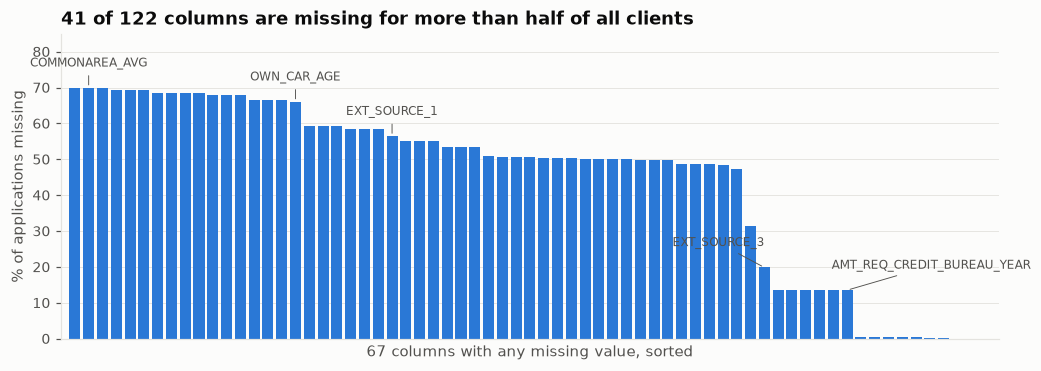

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(range(len(miss)), miss.values * 100, color=BLUE, width=0.8)
ax.set_xlim(-1, len(miss))
ax.set_xticks([])
ax.set_ylabel("% of applications missing")
ax.set_xlabel(f"{len(miss)} columns with any missing value, sorted")
ax.set_title(f"{(miss > 0.5).sum()} of {train.shape[1]} columns are missing for more than half of all clients")
for name, dx in [("COMMONAREA_AVG", 0), ("OWN_CAR_AGE", 0), ("EXT_SOURCE_1", 0),
                 ("EXT_SOURCE_3", -30), ("AMT_REQ_CREDIT_BUREAU_YEAR", 55)]:
    i = miss.index.get_loc(name)
    ax.annotate(name, (i, miss.iloc[i] * 100), xytext=(dx, 14), textcoords="offset points",
                ha="center", fontsize=8, color=INK_2, arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.6))
ax.set_ylim(0, 85)
save(fig, "eda_missing_share")
plt.show()

### Missing-data map: do columns go missing *together*?
Each row of the image is one client (random sample of 1,000, sorted by how many values they miss),
each column is a feature (sorted as above). Blue = missing.

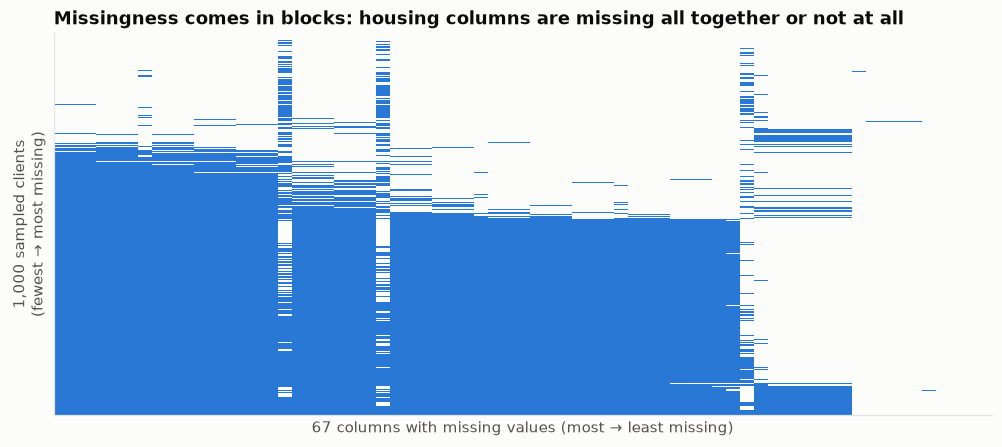

In [8]:
cols = miss.index
sample = train[cols].sample(1000, random_state=42)
mask = sample.isna()
mask = mask.loc[mask.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(11, 4.5))
cmap = plt.matplotlib.colors.ListedColormap([SURFACE, BLUE])
ax.imshow(mask.values, aspect="auto", cmap=cmap, interpolation="nearest")
ax.grid(False)
ax.set_yticks([])
ax.set_ylabel("1,000 sampled clients\n(fewest → most missing)")
ax.set_xticks([])
ax.set_xlabel(f"{len(cols)} columns with missing values (most → least missing)")
ax.set_title("Missingness comes in blocks: housing columns are missing all together or not at all")
save(fig, "eda_missing_map")
plt.show()

Which columns make up that block? The names share suffixes `_AVG`, `_MODE`, `_MEDI`: normalised
statistics about the client's **building** (size, age, floors, common area …).

In [9]:
housing = [c for c in train.columns if c.endswith(("_AVG", "_MODE", "_MEDI"))]
other = [c for c in cols if c not in housing]
print(f"Housing columns: {len(housing)}  |  missing share range: "
      f"{train[housing].isna().mean().min():.0%} – {train[housing].isna().mean().max():.0%}")
row_share = train[housing].isna().mean(axis=1)
print(f"Clients missing ALL housing columns: {(row_share == 1).mean():.1%}")
print(f"Clients missing NONE of them:        {(row_share == 0).mean():.1%}")
print(f"\nOther columns with missing values ({len(other)}):")
print(train[other].isna().mean().sort_values(ascending=False).map("{:.1%}".format).to_string())

Housing columns: 47  |  missing share range: 47% – 70%
Clients missing ALL housing columns: 47.4%
Clients missing NONE of them:        25.6%

Other columns with missing values (20):
OWN_CAR_AGE                   66.0%
EXT_SOURCE_1                  56.4%
OCCUPATION_TYPE               31.3%
EXT_SOURCE_3                  19.8%
AMT_REQ_CREDIT_BUREAU_HOUR    13.5%
AMT_REQ_CREDIT_BUREAU_DAY     13.5%
AMT_REQ_CREDIT_BUREAU_WEEK    13.5%
AMT_REQ_CREDIT_BUREAU_MON     13.5%
AMT_REQ_CREDIT_BUREAU_QRT     13.5%
AMT_REQ_CREDIT_BUREAU_YEAR    13.5%
NAME_TYPE_SUITE                0.4%
OBS_30_CNT_SOCIAL_CIRCLE       0.3%
DEF_30_CNT_SOCIAL_CIRCLE       0.3%
OBS_60_CNT_SOCIAL_CIRCLE       0.3%
DEF_60_CNT_SOCIAL_CIRCLE       0.3%
EXT_SOURCE_2                   0.2%
AMT_GOODS_PRICE                0.1%
AMT_ANNUITY                    0.0%
CNT_FAM_MEMBERS                0.0%
DAYS_LAST_PHONE_CHANGE         0.0%


## 3 · Is missingness itself related to default? (H2)
For each column (or block of columns that go missing together), split clients into
**value missing** vs **value present** and compare the default rate (= mean of `TARGET`) of the two groups.

A 95% confidence interval shows how sure we can be about each rate:
$\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$. Small groups → wide intervals.

In [10]:
flags = {
    "Housing block (all 47 cols)":         train[housing].isna().all(axis=1),
    "No credit-bureau file":               train["AMT_REQ_CREDIT_BUREAU_YEAR"].isna(),
    "OWN_CAR_AGE (= owns no car)":         train["OWN_CAR_AGE"].isna(),
    "EXT_SOURCE_1":                        train["EXT_SOURCE_1"].isna(),
    "OCCUPATION_TYPE":                     train["OCCUPATION_TYPE"].isna(),
    "EXT_SOURCE_3":                        train["EXT_SOURCE_3"].isna(),
    "EXT_SOURCE_2":                        train["EXT_SOURCE_2"].isna(),
}

rows = []
for name, is_missing in flags.items():
    g = train["TARGET"].groupby(is_missing).agg(["mean", "size"])
    p_miss, n_miss = g.loc[True]
    p_pres, n_pres = g.loc[False]
    rows.append({
        "feature": name,
        "missing share": n_miss / len(train),
        "n missing": int(n_miss),
        "default | present": p_pres,
        "default | missing": p_miss,
        "± 95% CI (missing)": 1.96 * np.sqrt(p_miss * (1 - p_miss) / n_miss),
        "difference (pp)": (p_miss - p_pres) * 100,
    })
miss_vs_target = pd.DataFrame(rows).set_index("feature")
miss_vs_target.style.format({
    "missing share": "{:.1%}", "n missing": "{:,}", "default | present": "{:.2%}",
    "default | missing": "{:.2%}", "± 95% CI (missing)": "±{:.2%}", "difference (pp)": "{:+.2f}",
})

,missing share,n missing,default | present,default | missing,± 95% CI (missing),difference (pp)
feature,,,,,,
Housing block (all 47 cols),47.4%,"145,755",7.00%,9.26%,±0.15%,+2.26
No credit-bureau file,13.5%,"41,519",7.72%,10.34%,±0.29%,+2.62
OWN_CAR_AGE (= owns no car),66.0%,"202,929",7.24%,8.50%,±0.12%,+1.26
EXT_SOURCE_1,56.4%,"173,378",7.50%,8.52%,±0.13%,+1.02
OCCUPATION_TYPE,31.3%,"96,391",8.79%,6.51%,±0.16%,-2.27
EXT_SOURCE_3,19.8%,"60,965",7.77%,9.31%,±0.23%,+1.55
EXT_SOURCE_2,0.2%,660,8.07%,7.88%,±2.06%,-0.19


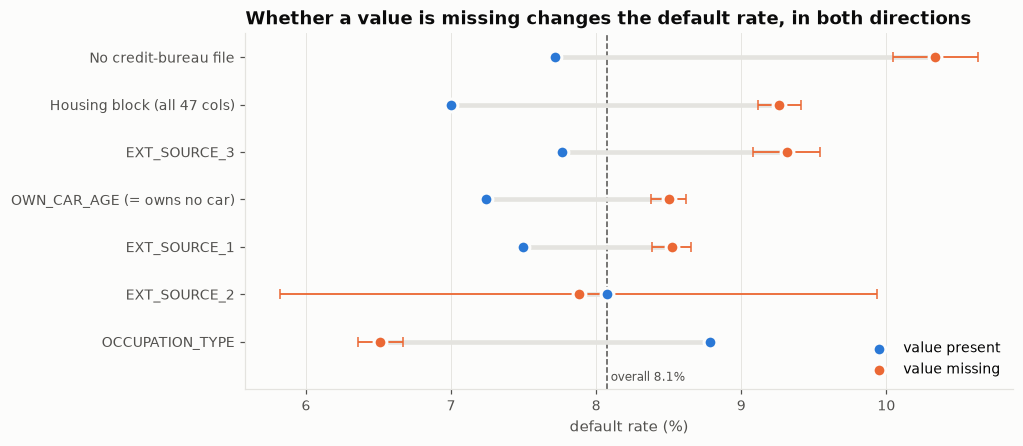

In [11]:
d = miss_vs_target.sort_values("difference (pp)")
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hlines(y, d["default | present"] * 100, d["default | missing"] * 100, color=GRID, lw=3, zorder=1)
ax.scatter(d["default | present"] * 100, y, s=70, color=BLUE, zorder=3, label="value present",
           edgecolor=SURFACE, linewidth=2)
ax.errorbar(d["default | missing"] * 100, y, xerr=d["± 95% CI (missing)"] * 100, fmt="none",
            ecolor=ORANGE, elinewidth=1.2, capsize=3, zorder=2)
ax.scatter(d["default | missing"] * 100, y, s=70, color=ORANGE, zorder=3, label="value missing",
           edgecolor=SURFACE, linewidth=2)
ax.axvline(base_rate * 100, color=INK_2, lw=1, ls="--", zorder=0)
ax.text(base_rate * 100, -0.75, f" overall {base_rate:.1%}", color=INK_2, fontsize=8, va="center")
ax.set_ylim(-1, len(d) - 0.5)
ax.set_yticks(y, d.index)
ax.set_xlabel("default rate (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Whether a value is missing changes the default rate, in both directions")
ax.legend(loc="lower right")
save(fig, "eda_missing_vs_default")
plt.show()

### Why would a *missing occupation* mean *lower* risk? A confounder.
`DAYS_EMPLOYED` holds a sentinel value, **365243** days (~1,000 years), for 55k clients.
Who are they, and do they overlap with the clients whose occupation is missing?

In [12]:
is_365243 = train["DAYS_EMPLOYED"] == 365243
occ_missing = train["OCCUPATION_TYPE"].isna()
print(pd.crosstab(is_365243.rename("DAYS_EMPLOYED == 365243"), occ_missing.rename("occupation missing")))
print("\nIncome type of the 365243 group:")
print(train.loc[is_365243, "NAME_INCOME_TYPE"].value_counts().loc[lambda s: s > 0].to_string())

occupation missing        False  True 
DAYS_EMPLOYED == 365243               
False                    211118  41019
True                          2  55372

Income type of the 365243 group:
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22


In [13]:
group = pd.Series(np.select([is_365243, occ_missing],
                            ["pensioner (365243, occupation missing)", "working, occupation missing"],
                            "working, occupation recorded"), index=train.index, name="group")
(train.assign(age=-train["DAYS_BIRTH"] / 365)
      .groupby(group)
      .agg(clients=("TARGET", "size"), mean_age=("age", "mean"), default_rate=("TARGET", "mean"))
      .style.format({"clients": "{:,}", "mean_age": "{:.1f}", "default_rate": "{:.2%}"}))

,clients,mean_age,default_rate
group,,,
"pensioner (365243, occupation missing)","55,374",59.8,5.40%
"working, occupation missing","41,019",40.5,8.02%
"working, occupation recorded","211,118",40.4,8.79%


**Finding.** 365243 is a sentinel for *pensioners* (55,352 of 55,374; the rest are unemployed), and pensioners
have no occupation recorded. Once they are separated, a missing occupation is no longer protective
(8.02% vs 8.07% overall): **the low risk belongs to pensioners (5.40%, mean age 60), not to the missing value.**

**Modelling consequence.** Left as is, 365243 sits ~365k units away from the normal range (−17k … 0).
Logistic regression fits one slope per feature, so this block of outliers distorts the slope for everyone;
a tree needs one split (`DAYS_EMPLOYED > 0`) and is unaffected. Feature engineering will replace the
sentinel with `NaN` and add an explicit `IS_PENSIONER` flag.

## 4 · Does default rate change *linearly* with key features? (H1)
Split each feature into **deciles** (10 groups with equal numbers of clients), then compute the default
rate in each decile. Equal-count bins mean every point is estimated from ~30k clients, so the shape is
not driven by a few extreme clients. Missing values are left out here (they were covered in section 3).

`CREDIT_TO_INCOME` is our first engineered feature: loan amount divided by yearly income.

In [14]:
train["AGE_YEARS"] = -train["DAYS_BIRTH"] / 365
train["CREDIT_TO_INCOME"] = train["AMT_CREDIT"] / train["AMT_INCOME_TOTAL"]

def decile_rates(col: str) -> pd.DataFrame:
    """Default rate per decile of `col`, with the decile's median value and a 95% CI."""
    d = train[[col, "TARGET"]].dropna()
    d["decile"] = pd.qcut(d[col], 10, labels=False, duplicates="drop")
    out = d.groupby("decile").agg(median_value=(col, "median"), clients=("TARGET", "size"),
                                  default_rate=("TARGET", "mean"))
    out["ci"] = 1.96 * np.sqrt(out.default_rate * (1 - out.default_rate) / out.clients)
    return out

features = {
    "AGE_YEARS": "Age (years)",
    "EXT_SOURCE_2": "EXT_SOURCE_2 (external score)",
    "EXT_SOURCE_3": "EXT_SOURCE_3 (external score)",
    "CREDIT_TO_INCOME": "Credit / income",
}
rates = {col: decile_rates(col) for col in features}

for col, r in rates.items():
    print(f"\n{col}")
    print(r.assign(default_rate=r.default_rate.map("{:.2%}".format), ci=r.ci.map("±{:.2%}".format),
                   median_value=r.median_value.round(2)).to_string())


AGE_YEARS
        median_value  clients default_rate      ci
decile                                            
0              25.77    30752       11.57%  ±0.36%
1              30.15    30760       10.99%  ±0.35%
2              34.01    30745        9.81%  ±0.33%
3              37.77    30759        8.85%  ±0.32%
4              41.29    30745        7.90%  ±0.30%
5              45.10    30764        7.79%  ±0.30%
6              49.42    30733        7.14%  ±0.29%
7              53.92    30758        6.34%  ±0.27%
8              58.40    30757        5.42%  ±0.25%
9              63.57    30738        4.90%  ±0.24%

EXT_SOURCE_2
        median_value  clients default_rate      ci
decile                                            
0               0.13    30686       18.35%  ±0.43%
1               0.28    30685       12.08%  ±0.36%
2               0.39    30687        9.96%  ±0.34%
3               0.48    30684        8.36%  ±0.31%
4               0.54    30684        7.42%  ±0.29%
5     

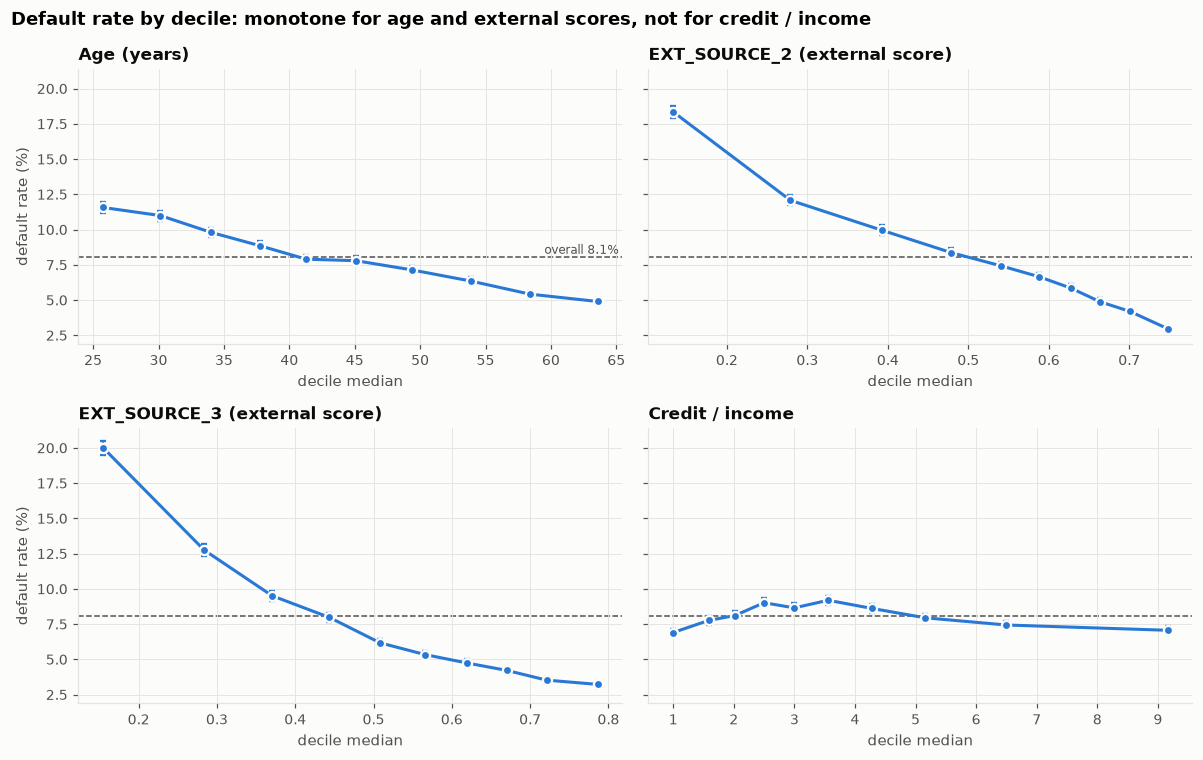

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for ax, (col, label) in zip(axes.flat, features.items()):
    r = rates[col]
    ax.errorbar(r.median_value, r.default_rate * 100, yerr=r.ci * 100, color=BLUE, marker="o",
                markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5, lw=2, capsize=2, elinewidth=1)
    ax.axhline(base_rate * 100, color=INK_2, lw=1, ls="--", zorder=0)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("decile median")
for ax in axes[:, 0]:
    ax.set_ylabel("default rate (%)")
axes[0, 0].text(axes[0, 0].get_xlim()[1], base_rate * 100, f"overall {base_rate:.1%} ", color=INK_2,
                fontsize=8, ha="right", va="bottom")
fig.suptitle("Default rate by decile: monotone for age and external scores, not for credit / income",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "eda_default_by_decile")
plt.show()

### The same curves on the scale logistic regression actually uses
Logistic regression is linear in the **log-odds** of default, $\log\frac{p}{1-p}$, not in the probability $p$.
A curve that bends in probability can be a straight line in log-odds, and then LogReg fits it perfectly.
The question for H1 is therefore: *which features are still curved in log-odds?*

To measure "straightness", fit a straight line to the 10 points (weighted by clients) and report $R^2$:
1.0 = perfectly straight, 0 = a line explains nothing.

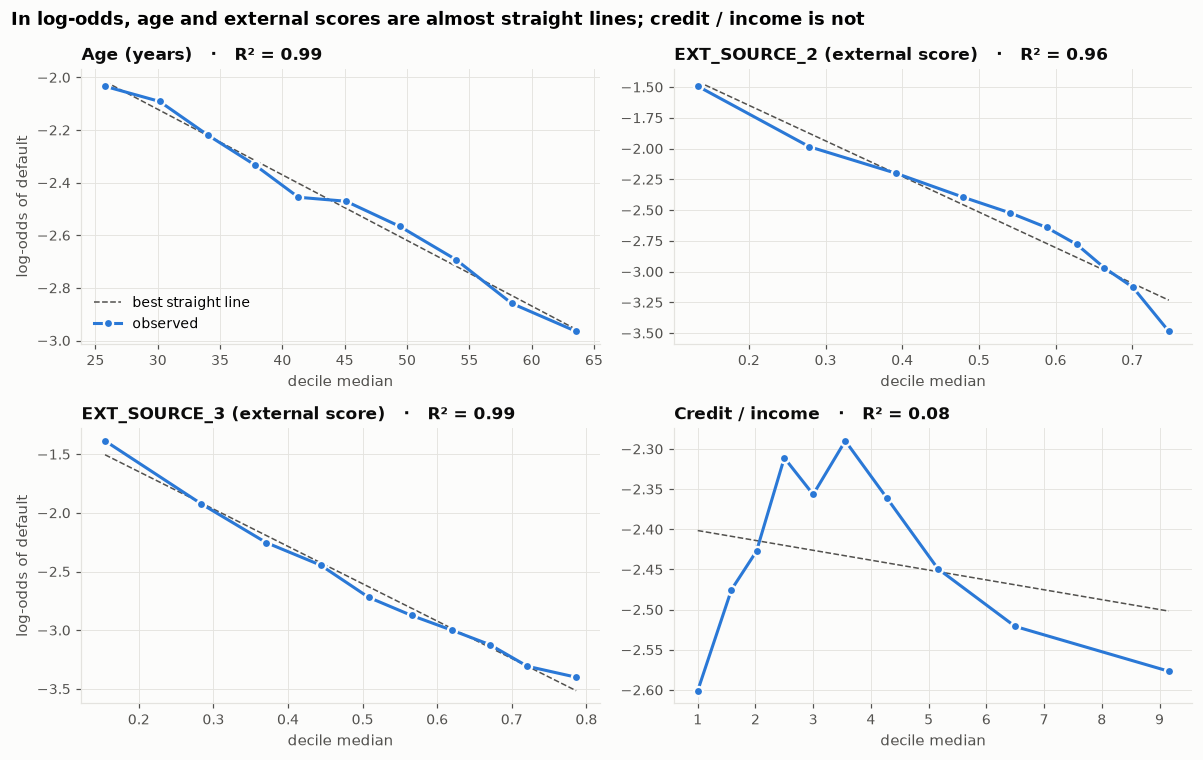

,R² of straight line (log-odds),"default rate, lowest decile","default rate, highest decile"
feature,,,
AGE_YEARS,0.990,11.57%,4.90%
EXT_SOURCE_2,0.959,18.35%,2.97%
EXT_SOURCE_3,0.988,20.00%,3.23%
CREDIT_TO_INCOME,0.081,6.91%,7.07%


In [16]:
def logit(p):
    return np.log(p / (1 - p))

def line_r2(x, y, w):
    coef = np.polyfit(x, y, 1, w=np.sqrt(w))
    resid = y - np.polyval(coef, x)
    ybar = np.average(y, weights=w)
    return 1 - np.sum(w * resid**2) / np.sum(w * (y - ybar) ** 2), coef

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
r2_rows = []
for ax, (col, label) in zip(axes.flat, features.items()):
    r = rates[col]
    x, y, w = r.median_value.values, logit(r.default_rate.values), r.clients.values
    r2, coef = line_r2(x, y, w)
    r2_rows.append({"feature": col, "R² of straight line (log-odds)": r2,
                    "default rate, lowest decile": r.default_rate.iloc[0],
                    "default rate, highest decile": r.default_rate.iloc[-1]})
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, np.polyval(coef, xs), color=INK_2, lw=1, ls="--", label="best straight line")
    ax.plot(x, y, color=BLUE, marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5,
            label="observed")
    ax.set_title(f"{label}   ·   R² = {r2:.2f}", fontsize=11)
    ax.set_xlabel("decile median")
for ax in axes[:, 0]:
    ax.set_ylabel("log-odds of default")
axes[0, 0].legend(loc="lower left")
fig.suptitle("In log-odds, age and external scores are almost straight lines; credit / income is not",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "eda_logodds_by_decile")
plt.show()

pd.DataFrame(r2_rows).set_index("feature").style.format(
    {"R² of straight line (log-odds)": "{:.3f}", "default rate, lowest decile": "{:.2%}",
     "default rate, highest decile": "{:.2%}"})

**Findings for H1.**
* **Age, EXT_SOURCE_2, EXT_SOURCE_3** are monotone and close to straight in log-odds: logistic regression can
  use them almost as well as a tree. The external scores are by far the strongest signals seen so far
  (lowest vs highest decile: ~18–20% vs ~3%).
* **Credit / income** rises to a peak around 3–4× income and falls again (inverted U). One slope cannot
  describe this, so raw LogReg will see almost no effect while a tree can split on both sides of the peak.
  Binning / WoE should recover it. A likely reason for the fall at high ratios is **selection**: the data
  only contains *approved* loans, and very large loans relative to income are approved only for clients
  the lender already trusts.